# Reto: Radar de Layer 2 — MATIC vs. índice L2

**Misión:** Polygon (MATIC) es una criptomoneda de Layer 2 cuyo precio parece moverse junto con el mercado L2. Vamos a **medir cuánto** (beta) y decidir si esa relación sirve para algo útil.

**Dataset:** `dataset_reto_l2.csv` — 120 días desde el 1-mar-2023, una fila por día. Es un dataset **sintético** creado para el reto, con la estructura del análisis real.

> **Cómo ejecutarlo:** abre este notebook en VS Code (o Jupyter/Colab) y ejecuta las celdas en orden (*Run All*). El dataset se lee de `../data/dataset_reto_l2.csv`.

> Unidades: los retornos están en **forma decimal**. 0.0189 = +1,89 % y −0.05 = −5 %. Cuando se habla de "1 %" en una fórmula se usa 0.01.

Estructura: un paso = una celda de código + una celda de texto con las respuestas.

## Paso 1. Entender y limpiar

**Objetivo:** asegurar que los datos están completos y bien tipados antes de calcular nada.

In [121]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Ruta del dataset: en el repositorio está en data/. En Colab, súbelo junto al notebook.
RUTA = Path("../data/dataset_reto_l2.csv")
if not RUTA.exists():
    RUTA = Path("dataset_reto_l2.csv")

# Estilo minimalista para todos los gráficos
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#E5E7EB", "axes.edgecolor": "#D1D5DB", "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "axes.prop_cycle": plt.cycler(color=["#2563EB", "#111827", "#EA580C"])})

df = pd.read_csv(RUTA, parse_dates=["fecha"])

print(df.shape)                      # filas y columnas
print(df.dtypes)                     # tipo de cada columna
print(df.head())                     # primeras filas
print(df.isna().sum())               # nulos por columna
print("Duplicados:", df.duplicated().sum())
print("Fechas repetidas:", df["fecha"].duplicated().sum())
# ¿un día por fila? Días entre una fecha y la siguiente
print(df["fecha"].diff().value_counts())
print("Rango:", df["fecha"].min().date(), "a", df["fecha"].max().date())
print(df.describe().round(4))

(120, 6)
fecha            datetime64[us]
precio_matic            float64
ret_matic               float64
ret_indice_l2           float64
ret_btc                 float64
volumen_musd            float64
dtype: object
       fecha  precio_matic  ret_matic  ret_indice_l2  ret_btc  volumen_musd
0 2023-03-01        1.0894    -0.0097         0.0000   0.0009          66.9
1 2023-03-02        1.1102     0.0189         0.0054  -0.0027          80.6
2 2023-03-03        1.1032    -0.0063        -0.0049  -0.0041          66.6
3 2023-03-04        1.0895    -0.0125        -0.0160  -0.0296          64.2
4 2023-03-05        1.0751    -0.0133        -0.0082  -0.0162          50.5
fecha            0
precio_matic     0
ret_matic        0
ret_indice_l2    0
ret_btc          0
volumen_musd     0
dtype: int64
Duplicados: 0
Fechas repetidas: 0
fecha
1 days    119
Name: count, dtype: int64
Rango: 2023-03-01 a 2023-06-28
                     fecha  precio_matic  ret_matic  ret_indice_l2   ret_btc  \
count      

In [122]:
# Comprobación extra 1: ¿ret_matic es de verdad el retorno logarítmico del precio?
ret_calc = np.log(df["precio_matic"] / df["precio_matic"].shift(1))
print("Máx. diferencia |ln(P_t/P_t-1) - ret_matic|:", round((ret_calc - df["ret_matic"]).abs().max(), 5))

# Comprobación extra 2: la primera fila
print(df.iloc[0])
print("Días con ret_indice_l2 exactamente 0:", (df["ret_indice_l2"] == 0).sum())

# ¿Cambia algo si quito la fila 1?
b_con, _ = np.polyfit(df["ret_indice_l2"], df["ret_matic"], 1)
b_sin, _ = np.polyfit(df["ret_indice_l2"].iloc[1:], df["ret_matic"].iloc[1:], 1)
print(f"beta con la fila 1 = {b_con:.4f} | beta sin la fila 1 = {b_sin:.4f}")

Máx. diferencia |ln(P_t/P_t-1) - ret_matic|: 0.00014
fecha            2023-03-01 00:00:00
precio_matic                  1.0894
ret_matic                    -0.0097
ret_indice_l2                    0.0
ret_btc                       0.0009
volumen_musd                    66.9
Name: 0, dtype: object
Días con ret_indice_l2 exactamente 0: 1
beta con la fila 1 = 0.7248 | beta sin la fila 1 = 0.7256


**Resultado del paso 1 (punto de control ✔):** 120 filas y 6 columnas, **0 nulos**, **0 duplicados** y las 119 diferencias entre fechas son exactamente de **1 día** (del 2023-03-01 al 2023-06-28, sin saltos). `fecha` se leyó como fecha y el resto como números decimales.

Comprobación adicional: `ret_matic` coincide con ln(precio_hoy / precio_ayer) con una diferencia máxima de 0,00014, que solo es redondeo a 4 decimales. Los datos son coherentes.

**El valor llamativo de la primera fila:** `ret_indice_l2 = 0.0` exacto el 2023-03-01. Es el **único** día de los 120 con un cero exacto, y es justamente el primer día (no hay día anterior en el archivo para calcular un retorno), así que lo más probable es que sea un **relleno** y no un movimiento real.

**Decisión: lo dejo**, porque (1) un 0 es un valor posible y neutro, (2) quitarlo apenas mueve la beta (0,7248 → 0,7256, una diferencia de 0,001) y (3) la guía trabaja con 120 filas (rangos de Excel 2:121 y corte de 90/30 días), así que mantenerlo hace los resultados comparables. Queda anotado como observación.

**Una frase por columna:**

| Columna | Qué es y en qué unidad |
|---|---|
| `fecha` | Día de la observación (fecha, frecuencia diaria). |
| `precio_matic` | Precio de cierre de MATIC en **dólares (USD)**; va de 1,11 a 0,74 USD. |
| `ret_matic` | Retorno diario **logarítmico** de MATIC, en **decimal** (0.01 = 1 %). |
| `ret_indice_l2` | Retorno diario del índice L2 (mediana de tokens L2), en **decimal**. |
| `ret_btc` | Retorno diario de Bitcoin, en **decimal**. |
| `volumen_musd` | Volumen negociado de MATIC en **millones de USD** por día (44,4 a 89,3). |

## Paso 2. Explorar

**Objetivo:** ver la relación con los ojos antes de medirla.

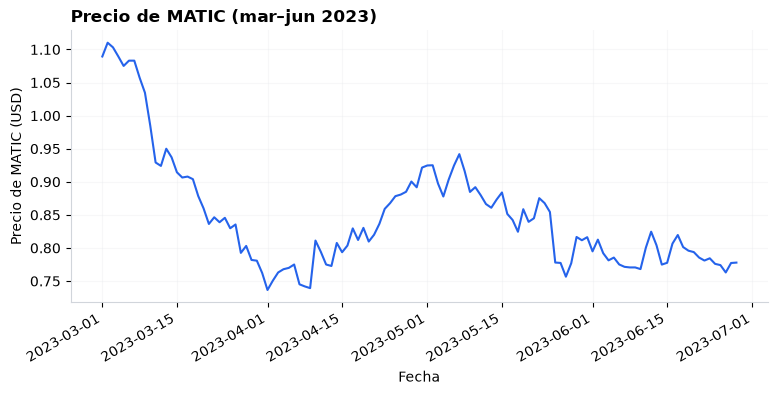

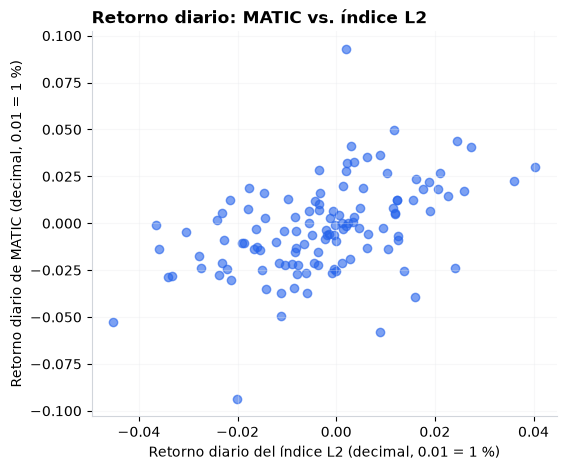

Correlación: 0.462


In [123]:
# 1) Precio en el tiempo
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(df["fecha"], df["precio_matic"])
ax.set_title("Precio de MATIC (mar–jun 2023)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio de MATIC (USD)")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

# 2) Dispersión de retornos
x = df["ret_indice_l2"]   # eje X: el mercado L2
y = df["ret_matic"]       # eje Y: MATIC
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(x, y, alpha=0.6)
ax.set_title("Retorno diario: MATIC vs. índice L2")
ax.set_xlabel("Retorno diario del índice L2 (decimal, 0.01 = 1 %)")
ax.set_ylabel("Retorno diario de MATIC (decimal, 0.01 = 1 %)")
ax.grid(alpha=0.3)
plt.show()

# 3) Correlación
corr = x.corr(y)
print("Correlación:", round(corr, 3))

**Resultado del paso 2 (punto de control ✔):** la correlación es **0,462**: está entre −1 y 1 y es positiva. La dispersión es una **nube inclinada hacia arriba**, no una línea.

- **Precio:** MATIC baja de 1,09 USD a 0,78 USD en el periodo (−29 %), con el mínimo el 1-abr (0,7365 USD). Se ven dos saltos bruscos: una subida el 10-abr y una caída el 25-may.
- **¿Débil, moderada o fuerte?** **Moderada**: cuando L2 sube, MATIC tiende a subir, pero hay mucha dispersión alrededor de esa tendencia.

## Paso 3. Medir la beta

**Objetivo:** convertir "se mueven juntos" en un número. Recta: `ret_matic = alpha + beta * ret_indice_l2`.

beta = 0.725 | alpha = -0.00097
R2 = 0.214


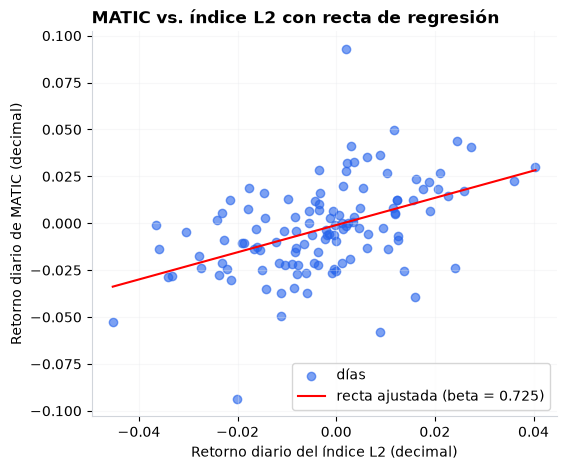

In [124]:
# np.polyfit(x, y, 1) devuelve primero la PENDIENTE (beta) y luego el INTERCEPTO (alpha).
beta, alpha = np.polyfit(x, y, 1)      # X = índice L2, Y = MATIC
print(f"beta = {beta:.3f} | alpha = {alpha:.5f}")

r2 = corr ** 2    # en regresión simple, R² = correlación al cuadrado
print(f"R2 = {r2:.3f}")

# Dibuja la recta sobre la dispersión
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(x, y, alpha=0.6, label="días")
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, alpha + beta * xs, color="red", label=f"recta ajustada (beta = {beta:.3f})")
ax.set_title("MATIC vs. índice L2 con recta de regresión")
ax.set_xlabel("Retorno diario del índice L2 (decimal)")
ax.set_ylabel("Retorno diario de MATIC (decimal)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [125]:
# Extra: ¿qué tan precisa es esa beta? (error estándar e intervalo aproximado del 95 %)
n = len(df)
res = y - (alpha + beta * x)
se_beta = np.sqrt((res ** 2).sum() / (n - 2) / ((x - x.mean()) ** 2).sum())
print(f"Error estándar de beta = {se_beta:.3f}")
print(f"IC 95 % aprox.: [{beta - 1.98 * se_beta:.2f}, {beta + 1.98 * se_beta:.2f}]")

Error estándar de beta = 0.128
IC 95 % aprox.: [0.47, 0.98]


**Resultado del paso 3 (punto de control ✔):** **beta = 0,725**, alpha = −0,00097, **R² = 0,214**. La beta es positiva y del orden de 1 (ni 0,01 ni 50), con X = índice L2 e Y = MATIC en el orden correcto.

**¿Cuánto se mueve MATIC por cada 1 % del mercado L2?** Por cada **1 %** que se mueve el índice L2, MATIC se mueve en promedio **0,72 %** en la misma dirección. MATIC es algo **menos sensible** que el mercado L2 en estos datos (beta < 1).

**¿Qué dice el R² sobre lo que NO explica el índice L2?** El índice L2 explica solo el **21 %** de la variación diaria de MATIC. El **79 % restante** se debe a factores propios de MATIC (noticias, eventos del proyecto, ruido) que el modelo no captura. Por eso la relación sirve para entender la tendencia, pero no para adivinar el retorno de un día concreto.

*Extra:* la beta es una estimación. Su error estándar es 0,13, así que un rango razonable es de **0,47 a 0,98**. Es claramente mayor que 0, pero no se conoce con precisión.

## Paso 4. Validar a ciegas

**Objetivo:** comprobar si la beta funciona con datos que el modelo **nunca vio**. Entrenamiento = primeros 90 días; prueba = últimos 30 días.

In [126]:
train = df.iloc[:90]    # días 1 a 90
test  = df.iloc[90:]    # días 91 a 120
print("Train:", train["fecha"].min().date(), "a", train["fecha"].max().date(), len(train), "días")
print("Test: ", test["fecha"].min().date(), "a", test["fecha"].max().date(), len(test), "días")

# 1) Ajusta SOLO con train
beta_tr, alpha_tr = np.polyfit(train["ret_indice_l2"], train["ret_matic"], 1)
print(f"beta (train) = {beta_tr:.3f} | alpha (train) = {alpha_tr:.5f}")

# 2) Predice en test
pred = alpha_tr + beta_tr * test["ret_indice_l2"]

# 3) RMSE
def rmse(real, predicho):
    return np.sqrt(np.mean((real - predicho) ** 2))

err_modelo = rmse(test["ret_matic"], pred)
err_base   = rmse(test["ret_matic"], 0)       # línea base: predecir siempre 0
print(f"RMSE modelo = {err_modelo:.5f}")
print(f"RMSE base   = {err_base:.5f}")
print(f"Mejora      = {1 - err_modelo / err_base:.1%}")
if err_modelo < err_base:
    print("El modelo le gana a la línea base.")
else:
    print("El modelo NO le gana a la línea base.")

Train: 2023-03-01 a 2023-05-29 90 días
Test:  2023-05-30 a 2023-06-28 30 días
beta (train) = 0.795 | alpha (train) = -0.00099
RMSE modelo = 0.01682
RMSE base   = 0.01819
Mejora      = 7.5%
El modelo le gana a la línea base.


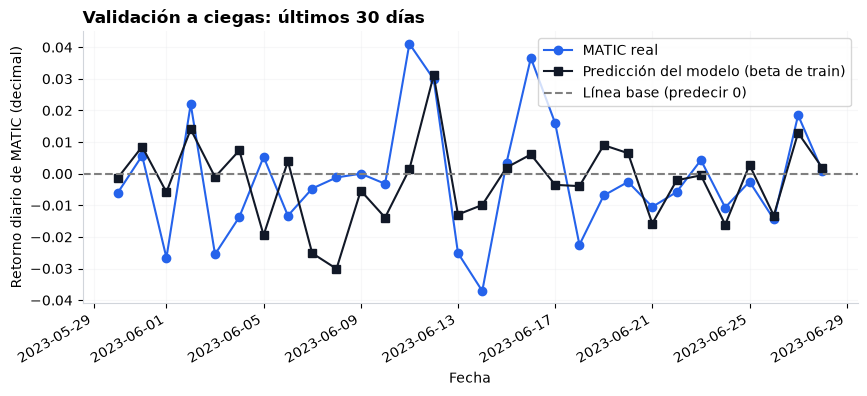

Mejora: IC 95 % bootstrap = [-15.3%, 23.8%]
En el 20% de los remuestreos el modelo NO gana
Días en que el modelo se acerca más que la línea base: 17 de 30


In [127]:
# Gráfico: real vs. predicho en los 30 días de prueba
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(test["fecha"], test["ret_matic"], marker="o", label="MATIC real")
ax.plot(test["fecha"], pred, marker="s", label="Predicción del modelo (beta de train)")
ax.axhline(0, color="gray", ls="--", label="Línea base (predecir 0)")
ax.set_title("Validación a ciegas: últimos 30 días")
ax.set_xlabel("Fecha")
ax.set_ylabel("Retorno diario de MATIC (decimal)")
ax.grid(alpha=0.3); ax.legend()
fig.autofmt_xdate()
plt.show()

# Extra de honestidad: ¿qué tan estable es esa mejora con solo 30 días? (bootstrap)
rng = np.random.default_rng(0)
e_mod = ((test["ret_matic"] - pred) ** 2).to_numpy()
e_base = (test["ret_matic"] ** 2).to_numpy()
mejoras = []
for _ in range(5000):
    i = rng.integers(0, 30, 30)        # remuestrear los 30 días con reemplazo
    mejoras.append(1 - np.sqrt(e_mod[i].mean()) / np.sqrt(e_base[i].mean()))
mejoras = np.array(mejoras)
print(f"Mejora: IC 95 % bootstrap = [{np.percentile(mejoras, 2.5):.1%}, {np.percentile(mejoras, 97.5):.1%}]")
print(f"En el {np.mean(mejoras <= 0):.0%} de los remuestreos el modelo NO gana")
dias_gana = (np.abs(test["ret_matic"] - pred) < np.abs(test["ret_matic"])).sum()
print("Días en que el modelo se acerca más que la línea base:", dias_gana, "de 30")

**Resultado del paso 4 (punto de control ✔):** con solo los primeros 90 días (1-mar a 29-may), **beta (train) = 0,795**. Es parecida a la del paso 3 (0,725), aunque no idéntica porque usa menos datos. Los dos RMSE están alrededor de 0,01–0,02.

| | RMSE en los 30 días de prueba (30-may a 28-jun) |
|---|---|
| Modelo (alpha + beta·L2) | **0,01682** |
| Línea base (predecir 0) | **0,01819** |
| Mejora | **7,5 %** |

**¿Le gana a la línea base?** Sí, por un **7,5 %**: el error típico baja de 1,82 % a 1,68 % diario.

**¿Me atrevería a decir que la diferencia es grande?** **No.** Es una mejora **modesta** y la medí con solo 30 días. Al remuestrear esos 30 días, la mejora puede ir de aproximadamente −15 % a +24 %, y en cerca de 1 de cada 5 remuestreos el modelo **no** gana. El modelo acierta mejor que la base en 17 de 30 días. Conclusión honesta: la beta aporta información real, pero poca para predecir el retorno de cada día. Además, el modelo usa el retorno de L2 **del mismo día**, que en la práctica no se conoce por adelantado.

## Paso 5. Usarlo

Se usa la beta del paso 3 (120 días). Hice **las dos opciones** (A escenario y B alertas) y también el bonus.

### Opción A: Escenario

In [128]:
shock = -0.10                 # -10 % en forma decimal
efecto = beta * shock
print(f"Si L2 cae 10 %, MATIC ≈ {efecto:.1%}")
print(f"(con alpha incluido: {alpha + beta * shock:.1%})")

# ¿Qué tan extremo es ese -10 % comparado con los datos?
print("Rango real del índice L2:", x.min(), "a", x.max())
print("Peor día de L2:", df.loc[x.idxmin(), "fecha"].date(), "| mejor día:", df.loc[x.idxmax(), "fecha"].date())
print(f"Desviación estándar diaria de L2 = {x.std():.4f} → -10 % son {abs(shock) / x.std():.1f} desviaciones")
print(f"-10 % es {shock / x.min():.1f} veces la peor caída diaria observada")

Si L2 cae 10 %, MATIC ≈ -7.2%
(con alpha incluido: -7.3%)
Rango real del índice L2: -0.0453 a 0.0404
Peor día de L2: 2023-03-27 | mejor día: 2023-06-12
Desviación estándar diaria de L2 = 0.0156 → -10 % son 6.4 desviaciones
-10 % es 2.2 veces la peor caída diaria observada


**Resultado de la opción A:** si el mercado L2 cae **10 %**, el modelo estima que MATIC cae alrededor de **7,2 %** (0,725 × −10 %). Con el alpha incluido, −7,3 %, casi lo mismo.

**¿Qué tan extremo es?** En los 120 días el índice L2 se movió solo entre **−4,53 %** (27-mar) y **+4,04 %** (12-jun). Una caída de −10 % es **2,2 veces la peor caída observada** y equivale a unas **6,4 desviaciones estándar**. Es una **extrapolación** fuera del rango que vio el modelo. El −7,2 % sirve como orden de magnitud, pero en un desplome real la relación podría ser distinta (en las crisis las correlaciones suelen subir).

### Opción B: Alertas

Residuo = ret_matic − beta × ret_indice_l2 (fórmula de la guía) = la parte del movimiento de MATIC que el mercado L2 no explica.

sigma = 0.0216 | umbral (2 sigma) = 0.0433
Días en alerta: 4
        fecha  ret_matic  ret_indice_l2   residuo  volumen_musd
10 2023-03-11    -0.0580         0.0088 -0.064378          76.2
37 2023-04-07    -0.0392         0.0159 -0.050724          79.8
40 2023-04-10     0.0929         0.0020  0.091450          89.3
85 2023-05-25    -0.0937        -0.0201 -0.079132          81.9


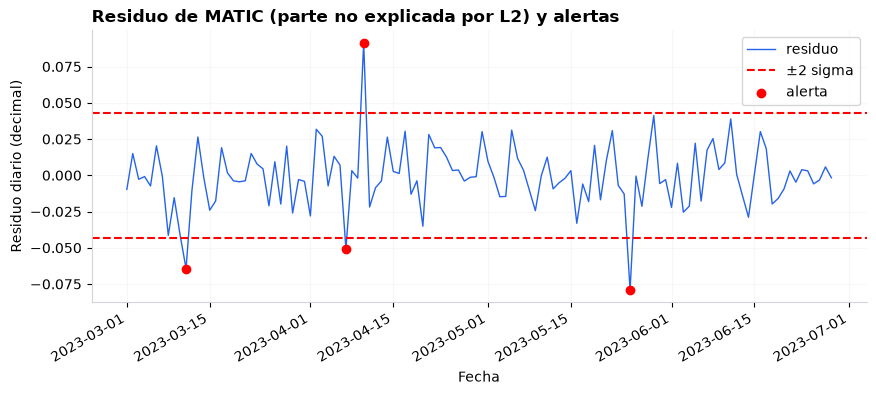

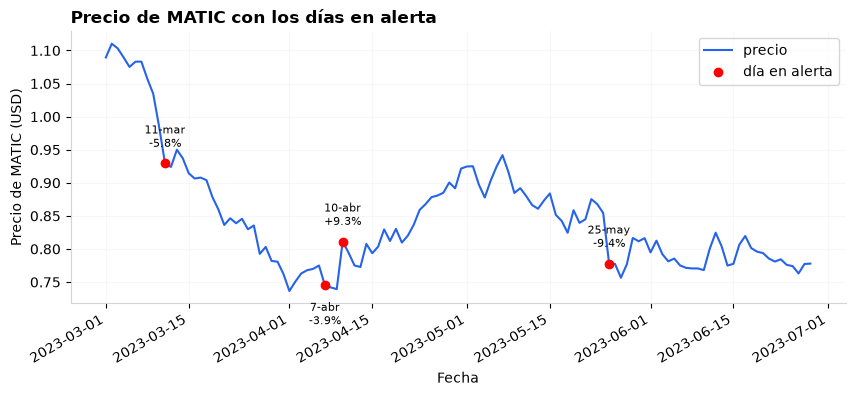

Alertas incluyendo alpha: 4


In [129]:
df["residuo"] = df["ret_matic"] - beta * df["ret_indice_l2"]
sigma = df["residuo"].std()
print(f"sigma = {sigma:.4f} | umbral (2 sigma) = {2 * sigma:.4f}")

alertas = df[df["residuo"].abs() > 2 * sigma]
print("Días en alerta:", len(alertas))
print(alertas[["fecha", "ret_matic", "ret_indice_l2", "residuo", "volumen_musd"]])

# Gráfico del residuo con las bandas de ±2 sigma
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df["fecha"], df["residuo"], lw=1, label="residuo")
ax.axhline(2 * sigma, color="red", ls="--", label="±2 sigma")
ax.axhline(-2 * sigma, color="red", ls="--")
ax.scatter(alertas["fecha"], alertas["residuo"], color="red", zorder=3, label="alerta")
ax.set_title("Residuo de MATIC (parte no explicada por L2) y alertas")
ax.set_xlabel("Fecha"); ax.set_ylabel("Residuo diario (decimal)")
ax.grid(alpha=0.3); ax.legend()
fig.autofmt_xdate()
plt.show()

# Los días de alerta sobre el gráfico del precio
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df["fecha"], df["precio_matic"], label="precio")
ax.scatter(alertas["fecha"], alertas["precio_matic"], color="red", zorder=3, label="día en alerta")
meses = {3: "mar", 4: "abr", 5: "may", 6: "jun"}
for _, r in alertas.iterrows():
    abajo = r["ret_matic"] < 0 and r["fecha"].day == 7      # evita que se pisen 7-abr y 10-abr
    ax.annotate(f"{r['fecha'].day}-{meses[r['fecha'].month]}\n{r['ret_matic']:+.1%}",
                (r["fecha"], r["precio_matic"]), textcoords="offset points",
                xytext=(0, -28 if abajo else 12), ha="center", fontsize=8)
ax.set_title("Precio de MATIC con los días en alerta")
ax.set_xlabel("Fecha"); ax.set_ylabel("Precio de MATIC (USD)")
ax.grid(alpha=0.3); ax.legend()
fig.autofmt_xdate()
plt.show()

# Comprobación: si incluyo alpha en el residuo, ¿cambian las alertas?
res_a = df["ret_matic"] - (alpha + beta * df["ret_indice_l2"])
print("Alertas incluyendo alpha:", (res_a.abs() > 2 * res_a.std()).sum())

**Resultado de la opción B (punto de control ✔):** σ del residuo = **0,0216**; umbral 2σ = **0,0433** (4,33 %). Hay **4 días en alerta**, un número entero pequeño:

| Fecha | ret_matic | ret L2 | Residuo | Volumen (M USD) |
|---|---|---|---|---|
| **2023-04-10** | **+9,29 %** | +0,20 % | **+9,15 %** | 89,3 (el máximo) |
| **2023-05-25** | **−9,37 %** | −2,01 % | **−7,91 %** | 81,9 |
| 2023-03-11 | −5,80 % | +0,88 % | −6,44 % | 76,2 |
| 2023-04-07 | −3,92 % | +1,59 % | −5,07 % | 79,8 |

**Los dos movimientos extremos propios de MATIC** son el **10-abr-2023** (+9,3 % con el mercado L2 casi plano) y el **25-may-2023** (−9,4 % cuando L2 solo cayó −2 %). En el gráfico del precio, el 10-abr es un **salto hacia arriba** (de 0,739 a 0,811 USD) que rompe la tendencia bajista. El 25-may es una **caída en escalón** (de 0,854 a 0,778 USD) que borra la subida de mayo. Los dos ocurren con volumen alto, como pasa con los eventos propios de un token. Los otros dos días en alerta son caídas de MATIC mientras L2 **subía**.

*Comprobación:* si se incluye alpha en el residuo, salen las mismas 4 alertas (alpha ≈ −0,001 es despreciable).

### Bonus: segundo factor (ret_btc)

Modelo: `ret_matic = alpha + b1 * ret_indice_l2 + b2 * ret_btc`

In [130]:
def ajustar(cols, datos):
    X = np.column_stack([np.ones(len(datos))] + [datos[c] for c in cols])
    coef, *_ = np.linalg.lstsq(X, datos["ret_matic"], rcond=None)
    return coef, X

def r2_ajustado(cols, datos):
    coef, X = ajustar(cols, datos)
    y_real = datos["ret_matic"]
    res = y_real - X @ coef
    n, k = X.shape
    r2 = 1 - (res ** 2).sum() / ((y_real - y_real.mean()) ** 2).sum()
    return r2, 1 - (1 - r2) * (n - 1) / (n - k), coef

for cols in (["ret_indice_l2"], ["ret_indice_l2", "ret_btc"]):
    r2_, r2_aj, coef = r2_ajustado(cols, df)
    print(cols)
    print("  R2 =", round(r2_, 3), "| R2 ajustado =", round(r2_aj, 3))
    print("  coef =", coef.round(3))
    # RMSE en los 30 días de prueba, ajustando solo con train
    coef_tr, _ = ajustar(cols, train)
    X_te = np.column_stack([np.ones(len(test))] + [test[c] for c in cols])
    print("  RMSE test =", round(rmse(test["ret_matic"], X_te @ coef_tr), 5))

print("Corr L2 vs BTC:", round(df["ret_indice_l2"].corr(df["ret_btc"]), 3))
print("Corr MATIC vs BTC (solo):", round(df["ret_matic"].corr(df["ret_btc"]), 3))
r_lb = df["ret_indice_l2"].corr(df["ret_btc"])
print("VIF =", round(1 / (1 - r_lb ** 2), 2))

['ret_indice_l2']
  R2 = 0.214 | R2 ajustado = 0.207
  coef = [-0.001  0.725]
  RMSE test = 0.01682
['ret_indice_l2', 'ret_btc']
  R2 = 0.234 | R2 ajustado = 0.221
  coef = [-0.002  0.956 -0.374]
  RMSE test = 0.01605
Corr L2 vs BTC: 0.717
Corr MATIC vs BTC (solo): 0.232
VIF = 2.06


**Resultado del bonus:**

| Modelo | R² | R² ajustado | RMSE prueba (30 días) |
|---|---|---|---|
| Solo L2 | 0,214 | 0,207 | 0,01682 |
| L2 + BTC | 0,234 | **0,221** | **0,01605** |

Agregar BTC **mejora un poco** el ajuste: el R² ajustado sube de 0,207 a 0,221 (sigue subiendo aunque se penaliza la variable extra) y el RMSE de prueba baja de 0,01682 a 0,01605. La mejora es pequeña.

**Lo raro:** el coeficiente de BTC sale **negativo** (b2 = −0,374) aunque, por sí sola, la correlación MATIC–BTC es positiva (0,23). Además, b1 sube de 0,725 a 0,956. Esto se explica porque **L2 y BTC están muy correlacionados (0,717)**.

**¿Qué problema causa que dos factores se parezcan tanto?** **Multicolinealidad:** el modelo no puede separar bien qué parte del movimiento viene de cada factor. Los coeficientes se vuelven **inestables** (cambian mucho con pocos datos: en train b2 = −0,29), pueden **cambiar de signo** y pierden interpretación. b2 negativo no significa que "MATIC baje cuando sube BTC". Significa que, *manteniendo L2 fijo*, BTC corrige el exceso de la beta. Por eso, para comunicar el resultado, me quedo con el modelo simple de una variable.

## Errores comunes: revisión antes de entregar

- ✔ La recta se ajustó con **retornos**, no con `precio_matic`.
- ✔ X e Y en el orden correcto: `np.polyfit(x=L2, y=MATIC)`; en Excel `PENDIENTE(Y=C; X=D)`.
- ✔ La beta del paso 4 usa **solo los primeros 90 días**.
- ✔ Decimales: el shock de −10 % se escribió como −0.10.
- ✔ Todos los gráficos tienen título, ejes y unidades.
- ✔ No digo que el modelo "predice bien" sin compararlo: se comparó con la línea base y la mejora es modesta.

## Resumen (plantilla)

| Sección | Frase |
|---|---|
| **Mi beta** | Por cada 1 % que se mueve el mercado L2, MATIC se mueve en promedio **0,72 %**. La correlación es **0,46** y el R² es **0,21**. |
| **Validación** | Con beta calculada solo con 90 días, el RMSE en los 30 días de prueba fue **0,0168** frente a **0,0182** de la línea base (predecir 0). Mi modelo **gana** por **7,5 %**. |
| **Uso práctico** | (Escenario) Si L2 cae 10 %, MATIC cae ≈ **7,2 %**. (Alertas) Encontré **4** días con \|residuo\| > 2σ, entre ellos **10-abr-2023** y **25-may-2023**. |
| **Limitación** | Una limitación importante es que **la prueba tiene solo 30 días**, **porque** con tan pocos días la mejora de 7,5 % no es estable: al remuestrear puede ir de −15 % a +24 % y en 1 de cada 5 casos el modelo no gana. Además, el R² de 0,21 deja sin explicar el 79 % del movimiento. |